### Exercice 8 — Arbres de décision et forêts aléatoires

In [51]:
from sklearn.datasets import make_classification

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier 

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score ,f1_score

from sklearn.tree import plot_tree

import matplotlib.pyplot as plt

import pandas as pd


### Generation du dataset

In [52]:
x , y = make_classification(n_samples=800, n_features=15, n_informative=8, n_redundant=3, n_classes=4, random_state=1)

In [53]:
feature_name = [f"feature_{i}" for i in range(1,16)]

x = pd.DataFrame(x,columns=feature_name)


### Separation du train et du test set

In [54]:
x_train , x_test , y_train , y_test =  train_test_split(x, y, test_size=0.25)

### Entrainement d'un DecisionTreeClassifier

In [55]:
model1 = DecisionTreeClassifier(max_depth=5, random_state=1)

model1.fit(x_train,y_train)

model1.score(x_train,y_train)

model1.score(x_test,y_test)

dtc_pred =  model1.predict(x_test)

### Entrainement d'un RandomForestClassifier

In [56]:
model2 = RandomForestClassifier(n_estimators=200, random_state=1)

model2.fit(x_train,y_train)

model2.score(x_train,y_train)

model2.score(x_test,y_test)

rfc_pred =  model2.predict(x_test)

### Comparaison des accuracy et F1-macro sur le test dans un tableau Pandas

In [57]:
df =  pd.DataFrame({

    "model" : ["DecisionTreeClassifier","RandomForestClassifier"],

    "accuracy" : [accuracy_score(y_test,dtc_pred), accuracy_score(y_test,rfc_pred)],

    "f1_score" : [f1_score(y_test,dtc_pred,average="weighted"),f1_score(y_test,rfc_pred,average="weighted")]

})

df

,model,accuracy,f1_score
0,DecisionTreeClassifier,0.57,0.570029
1,RandomForestClassifier,0.72,0.720385


### Visualisation de l'arbre de decision

[Text(0.5, 0.9, 'feature_5 <= -1.242\ngini = 0.75\nsamples = 600\nvalue = [155.0, 155.0, 145.0, 145.0]\nclass = Classe 0'),
 Text(0.25, 0.7, 'feature_8 <= -0.611\ngini = 0.696\nsamples = 215\nvalue = [11, 66, 75, 63]\nclass = Classe 2'),
 Text(0.375, 0.8, 'True  '),
 Text(0.125, 0.5, 'feature_11 <= 0.559\ngini = 0.632\nsamples = 108\nvalue = [8, 27, 57, 16]\nclass = Classe 2'),
 Text(0.0625, 0.3, 'feature_1 <= -5.224\ngini = 0.567\nsamples = 80\nvalue = [6, 9, 49, 16]\nclass = Classe 2'),
 Text(0.03125, 0.1, '\n  (...)  \n'),
 Text(0.09375, 0.1, '\n  (...)  \n'),
 Text(0.1875, 0.3, 'feature_3 <= 2.275\ngini = 0.5\nsamples = 28\nvalue = [2, 18, 8, 0]\nclass = Classe 1'),
 Text(0.15625, 0.1, '\n  (...)  \n'),
 Text(0.21875, 0.1, '\n  (...)  \n'),
 Text(0.375, 0.5, 'feature_12 <= -0.656\ngini = 0.645\nsamples = 107\nvalue = [3, 39, 18, 47]\nclass = Classe 3'),
 Text(0.3125, 0.3, 'feature_3 <= 1.497\ngini = 0.396\nsamples = 42\nvalue = [1, 32, 4, 5]\nclass = Classe 1'),
 Text(0.28125, 0.1,

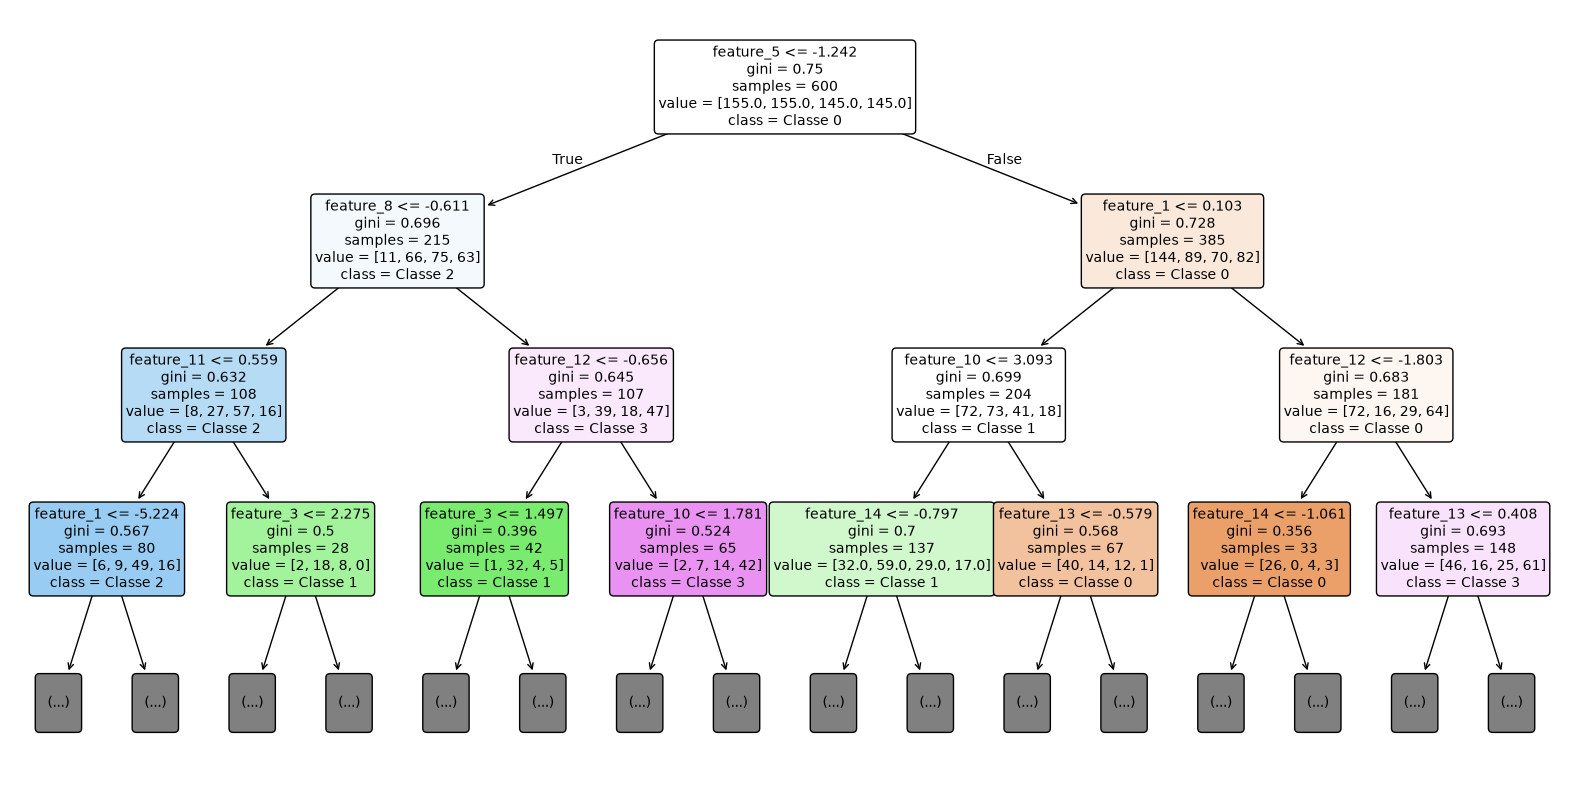

In [61]:


plt.figure(figsize=(20, 10))

plot_tree(
    model1,
    feature_names=x.columns,
    class_names=["Classe 0", "Classe 1", "Classe 2", "Classe 3"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=10
)

### 15 feature_importances_ de la forêt aléatoire sous forme de barres triées

<BarContainer object of 15 artists>

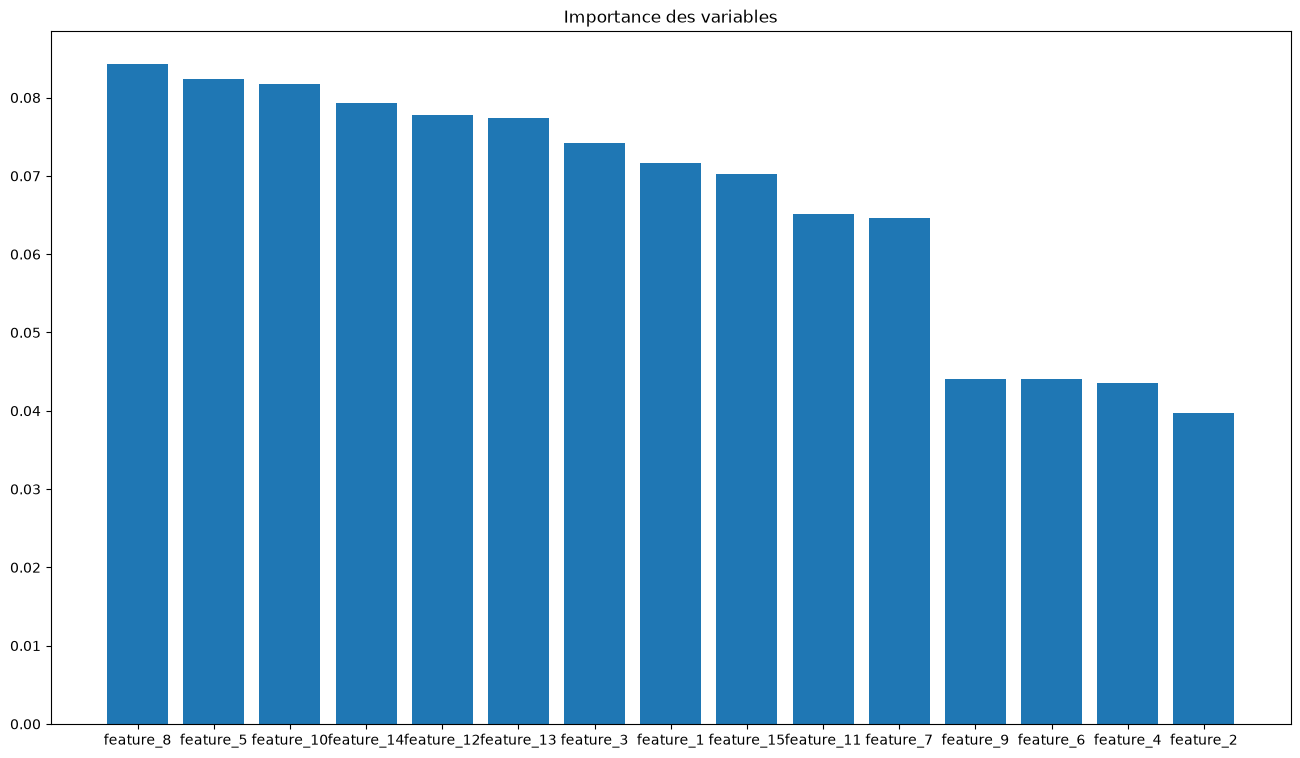

In [71]:
df = pd.DataFrame({

    "variable" :  feature_name ,

    "importance" : model2.feature_importances_

})

df = df.sort_values(by="importance", ascending=False)

fig , ax = plt.subplots(figsize=(16,9))

ax.set_title("Importance des variables")

ax.bar(df["variable"], df["importance"])

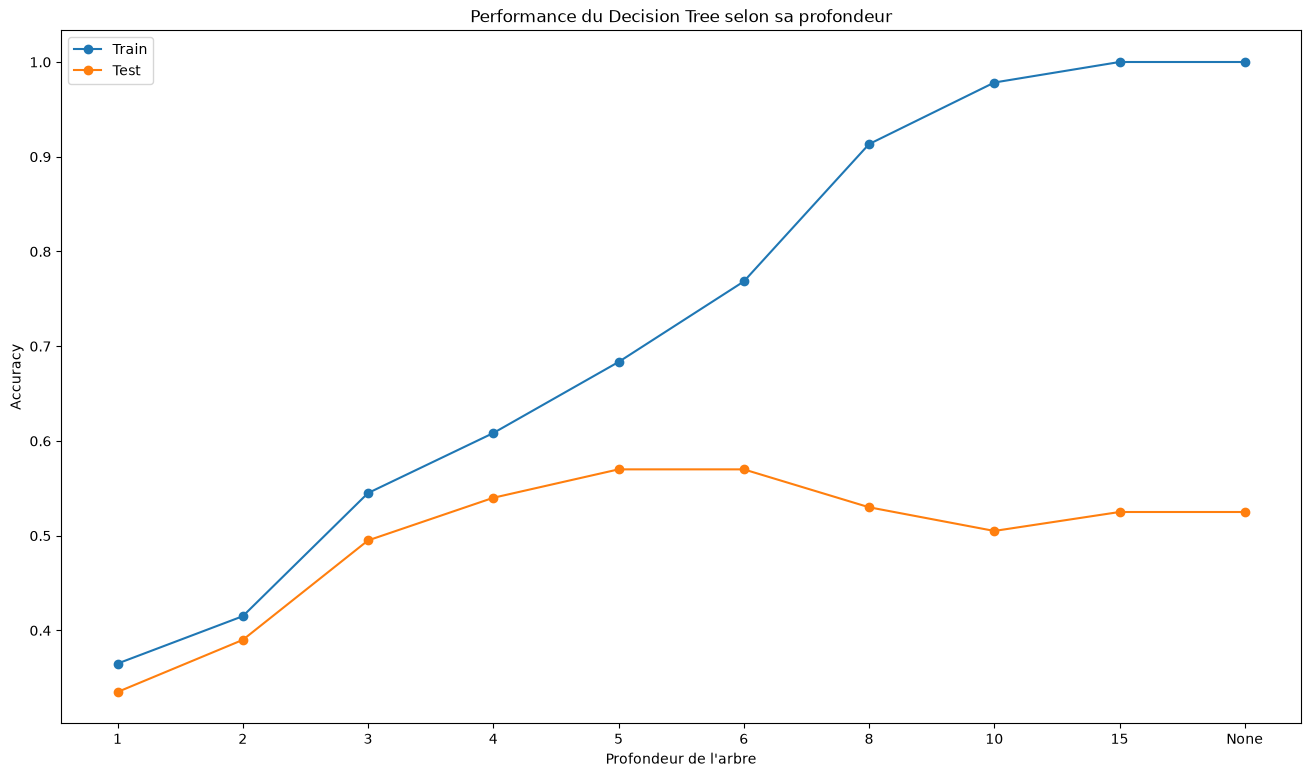

In [95]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, None]

acc_train = []

acc_test = []

for depth in depths :

    model = DecisionTreeClassifier(max_depth=depth, random_state=1)

    model.fit(x_train,y_train)

    pred_train = model.predict(x_train)

    pred_test = model.predict(x_test)

    acc_train.append(accuracy_score(pred_train, y_train))

    acc_test.append(accuracy_score(pred_test, y_test))

fig , ax = plt.subplots(figsize=(16,9))

lab = ['1', '2', '3', '4', '5', '6', '8', '10', '15', 'None']

ax.plot(lab,acc_train , label="Train",  marker='o')

ax.plot(lab,acc_test , label="Test", marker='o')

ax.set_xlabel("Profondeur de l'arbre")

ax.set_ylabel("Accuracy")

ax.set_title("Performance du Decision Tree selon sa profondeur")

ax.legend()
